# Predicted vs. true perturbed cells — lupus patients, out-of-sample

For a held-out patient, each method predicts IFN-β-stimulated cells from that patient's control cells
(trained on the 7 other patients). This notebook compares those predictions with the patient's real stimulated cells.

Methods (hyper-parameters chosen by leave-one-patient-out inside the training patients):

| name | what it is |
|---|---|
| `WPT kernel`, `BW kernel` | kernel regression of parallel-transported tangent vectors (note Sec. 2.1), with WPT⁻ / Bures–Wasserstein |
| `WPT linear`, `BW linear` | linear regression at the barycenter pivot, with intercept (Sec. 2.2) |
| `WPT linear-nointercept`, `BW linear-nointercept` | Sec. 2.2 exactly as written (no intercept) |
| `mean-shift` | add the average training effect in gene space |
| `identity` | no perturbation (the control cells themselves) |

CellOT's predicted cells are not shown: no trained weights are published, only its MMD values (last figure).
Run `scripts/run_fold.py` and `scripts/eval_fold.py` first (outputs in `results/`).

In [1]:
import os, sys, warnings
warnings.filterwarnings("ignore")
ROOT = os.path.abspath("..") if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
sys.path.insert(0, ROOT)
import numpy as np, pandas as pd, matplotlib.pyplot as plt, umap
from scipy.stats import gaussian_kde
from wreg.predict import load_predictions
from wreg.evaluate import mmd

METHODS = ["WPT kernel", "WPT linear", "BW kernel", "BW linear",
           "WPT linear-nointercept", "BW linear-nointercept", "mean-shift", "identity"]
TRUTH, PRED, CTRL = "#8a8a84", "#2a78d6", "#eb6834"   # truth = gray, prediction = blue, control = orange
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": False, "font.size": 9, "axes.titlesize": 10, "legend.frameon": False})
rng = np.random.RandomState(0)
def sub(df, n=1000):
    return df if len(df) <= n else df.iloc[rng.choice(len(df), n, replace=False)]

## Figure functions

In [2]:
def embed_panels(D, K, kind="umap"):
    """Small multiples: true stimulated cells (gray) with each method's predicted cells (blue) on top.
    The embedding is fit once on control + true stimulated cells (top-50 marker genes); predictions are projected into it."""
    mk = D["markers"]; ctrl, truth = sub(D["control"])[mk], sub(D["truth"])[mk]
    ref = np.vstack([ctrl.values, truth.values])
    if kind == "umap":
        emb = umap.UMAP(n_neighbors=30, min_dist=0.3, random_state=0).fit(ref); f = emb.transform
    else:
        mu = ref.mean(0); _, _, Vt = np.linalg.svd(ref - mu, full_matrices=False); f = lambda X: (X - mu) @ Vt[:2].T
    zt, zc = f(truth.values), f(ctrl.values)
    fig, axes = plt.subplots(2, 4, figsize=(13, 6.4), sharex=True, sharey=True)
    for ax, m in zip(axes.ravel(), METHODS):
        zp = f(D["preds"][m].loc[ctrl.index, mk].values)
        ax.scatter(*zt.T, s=3, c=TRUTH, alpha=0.45, linewidths=0, label="true stimulated", rasterized=True)
        ax.scatter(*zp.T, s=3, c=PRED, alpha=0.45, linewidths=0, label="predicted", rasterized=True)
        score = mmd(truth.values, D["preds"][m].loc[ctrl.index, mk].values)
        ax.set_title(f"{m}\nMMD {score:.4f}"); ax.set_xticks([]); ax.set_yticks([])
    axes[0, 0].legend(markerscale=4, loc="best")
    name = "UMAP" if kind == "umap" else "PCA"
    fig.suptitle(f"Patient {K}: predicted vs. true stimulated cells, {name} of top-50 marker genes "
                 f"(identity panel = control cells)", y=1.0)
    fig.tight_layout(); plt.show()

def marginal_panels(D, K, genes):
    """Rows = genes, columns = methods. Density of expression: true stimulated (gray fill), control (orange dashed), predicted (blue)."""
    methods = METHODS[:4] + ["mean-shift"]
    fig, axes = plt.subplots(len(genes), len(methods), figsize=(2.5 * len(methods), 1.5 * len(genes)), sharex="row", squeeze=False)
    for i, g in enumerate(genes):
        t, c = D["truth"][g].values, D["control"][g].values
        allv = np.concatenate([t, c] + [D["preds"][m][g].values for m in methods])
        xs = np.linspace(*np.quantile(allv, [0.005, 0.995]), 200)
        kde = lambda v: gaussian_kde(v + 1e-6 * rng.randn(len(v)))(xs)
        kt, kc = kde(t), kde(c)
        for j, m in enumerate(methods):
            ax = axes[i, j]
            ax.fill_between(xs, kt, color=TRUTH, alpha=0.35, linewidth=0, label="true stimulated")
            ax.plot(xs, kc, color=CTRL, lw=1.2, ls="--", label="control")
            kp = kde(D["preds"][m][g].values)
            ax.plot(xs, kp, color=PRED, lw=2, label="predicted")
            ax.set_ylim(0, 1.25 * max(kt.max(), kp.max()))  # control spike may be clipped
            ax.set_yticks([]); ax.spines["left"].set_visible(False)
            if i == 0: ax.set_title(m)
            if j == 0: ax.set_ylabel(D["symbols"].get(g, g), rotation=0, ha="right", va="center")
    fig.legend(*axes[0, 0].get_legend_handles_labels(), loc="upper center", ncol=3, bbox_to_anchor=(0.5, 0.985))
    fig.suptitle(f"Patient {K}: marginal expression of the top marker genes (scaled expression; control peak clipped)", y=1.0)
    fig.tight_layout(rect=(0, 0, 1, 0.965)); plt.show()

def mean_var_panels(D, K):
    """Per-gene mean (top row) and standard deviation (bottom row) over the top-50 marker genes: predicted vs. true."""
    mk = D["markers"]; methods = METHODS[:4] + ["mean-shift", "identity"]
    fig, axes = plt.subplots(2, len(methods), figsize=(2.3 * len(methods), 4.8))
    for r, (stat, lab) in enumerate([(lambda d: d.mean(0), "mean"), (lambda d: d.std(0), "std")]):
        t = stat(D["truth"][mk])
        for ax, m in zip(axes[r], methods):
            p = stat(D["preds"][m][mk])
            lo, hi = min(t.min(), p.min()), max(t.max(), p.max())
            ax.plot([lo, hi], [lo, hi], color="#c3c2b7", lw=1, zorder=0)
            ax.scatter(t, p, s=14, c=PRED, edgecolors="white", linewidths=0.5)
            ax.set_title(f"{m}\nr = {np.corrcoef(t, p)[0, 1]:.3f}" if r == 0 else f"r = {np.corrcoef(t, p)[0, 1]:.3f}")
            ax.set_xlabel(f"true {lab}");
            if ax is axes[r][0]: ax.set_ylabel(f"predicted {lab}")
    fig.suptitle(f"Patient {K}: per-gene {'mean and spread'} of the top-50 marker genes", y=1.0)
    fig.tight_layout(); plt.show()

def report(K):
    D = load_predictions(K)
    print(f"patient {K}: {len(D['control'])} control test cells, {len(D['truth'])} stimulated test cells")
    display(D["selected"].rename(columns={"d": "PCA dim", "hyper": "bandwidth / ridge", "mmd": "inner-CV MMD"})
            .set_index(["geom", "method"])[["PCA dim", "bandwidth / ridge", "inner-CV MMD"]].round(4))
    embed_panels(D, K, "umap"); embed_panels(D, K, "pca")
    marginal_panels(D, K, D["markers"][:6]); mean_var_panels(D, K)

## Held-out patient 1488

patient 1488: 1208 control test cells, 1427 stimulated test cells


PCA dim  bandwidth / ridge  inner-CV MMD
geom method                                                      
bw   kernel                   50              0.500        0.0114
     linear                   50              0.001        0.0107
     linear-nointercept       50              1.000        0.0413
wpt  kernel                   50              0.100        0.0098
     linear                   30              0.001        0.0110
     linear-nointercept       50              0.001        0.0284

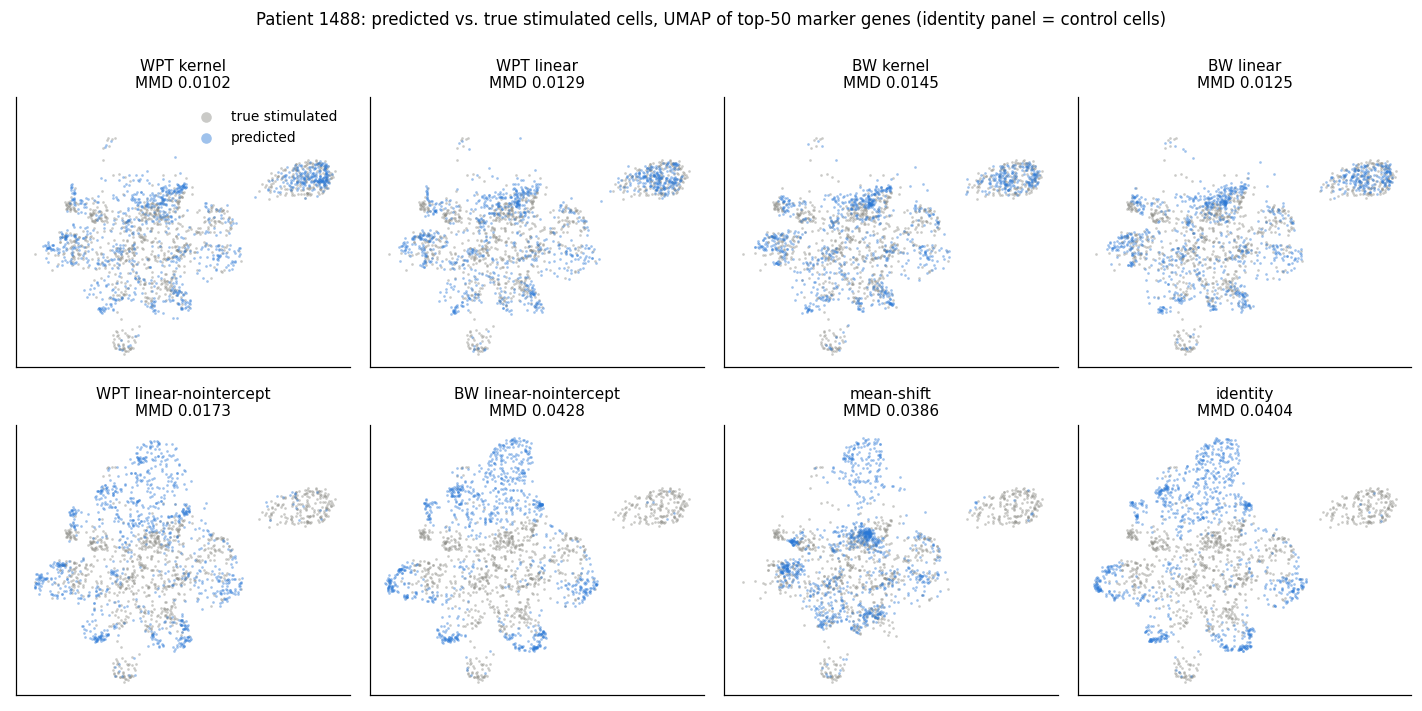

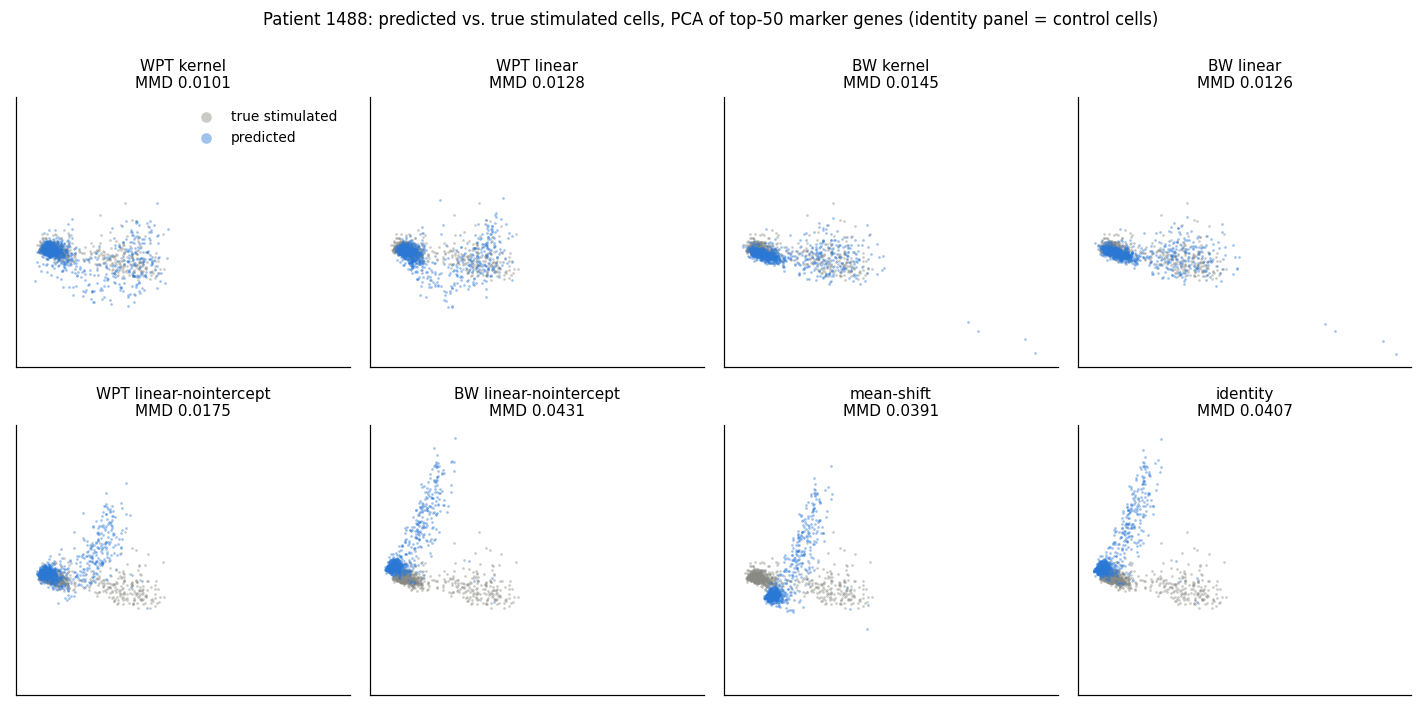

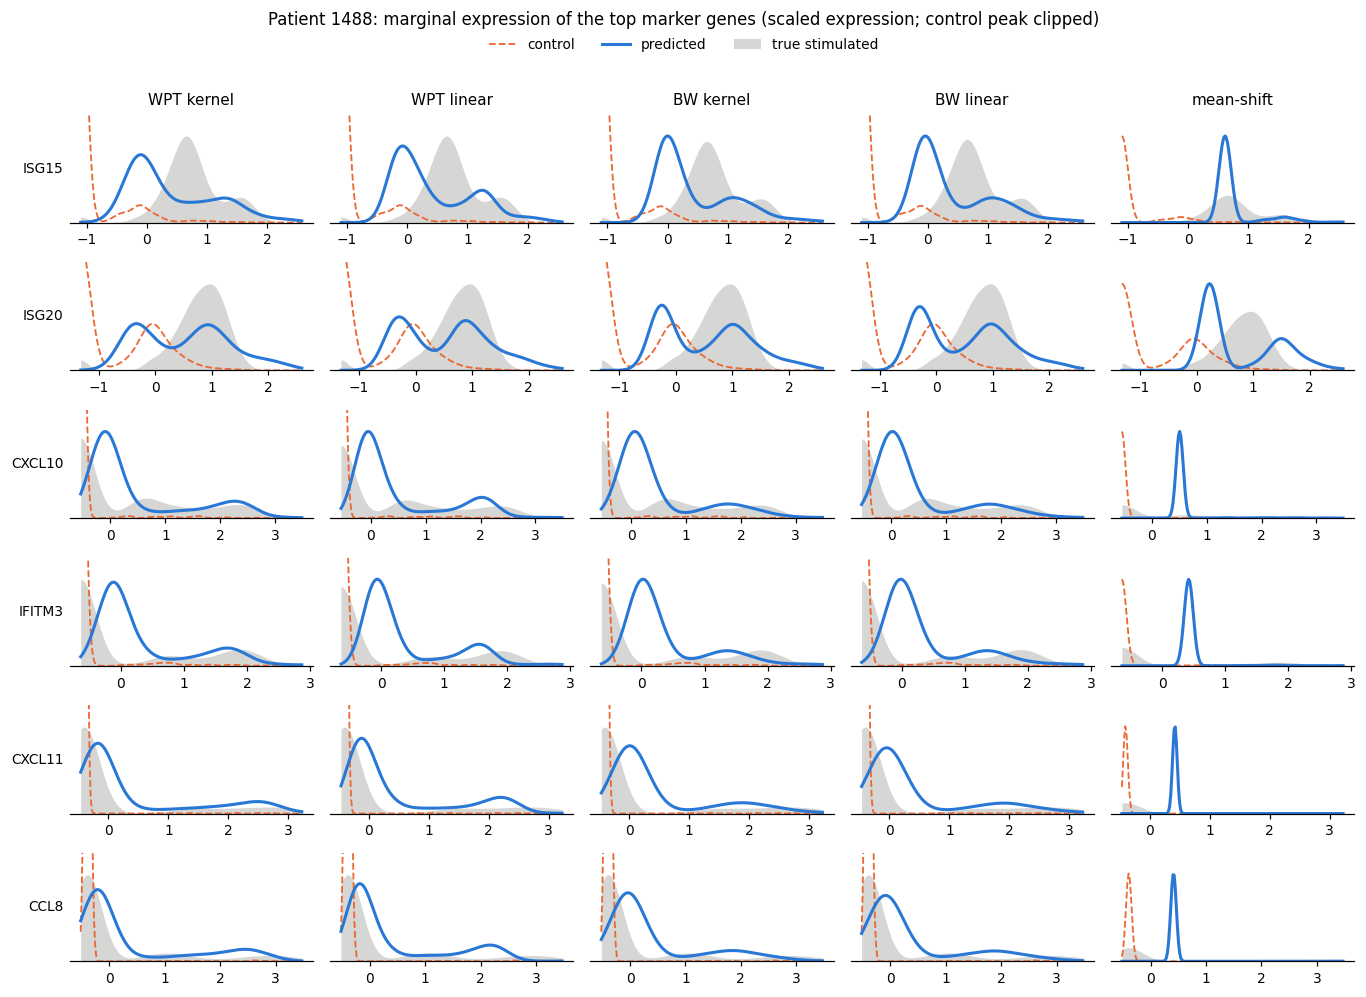

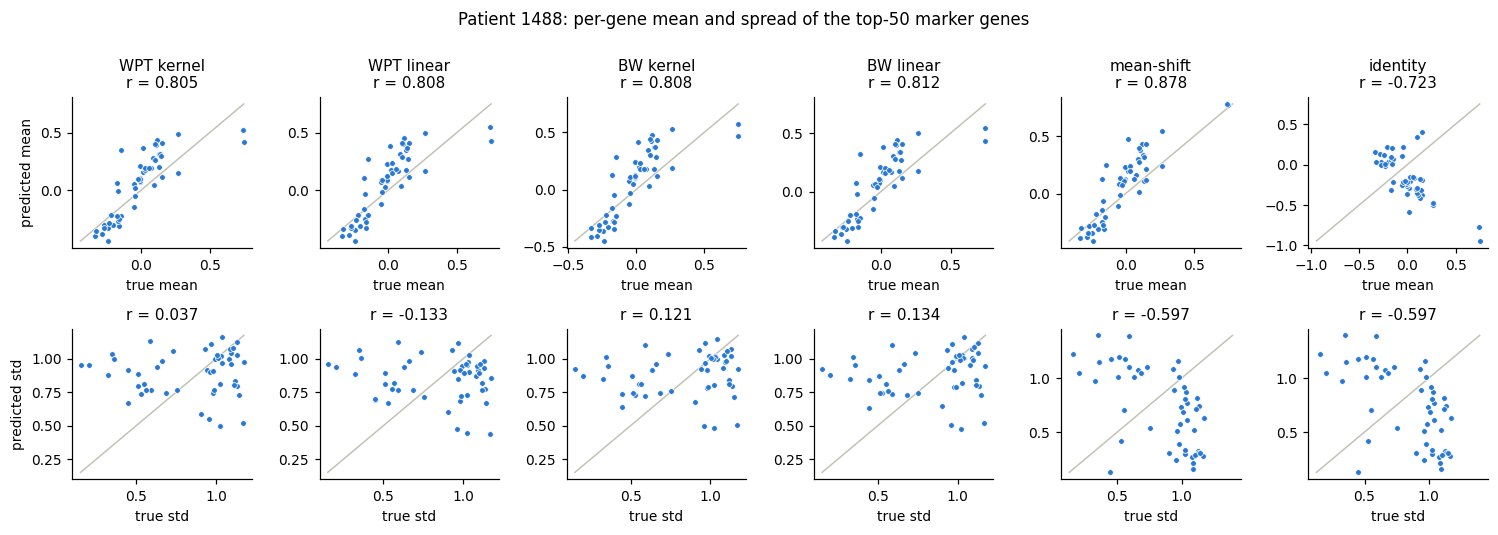

In [3]:
report(1488)

## Held-out patient 1015

patient 1015: 1596 control test cells, 1334 stimulated test cells


PCA dim  bandwidth / ridge  inner-CV MMD
geom method                                                      
bw   kernel                   30              0.100        0.0105
     linear                   50              0.001        0.0104
     linear-nointercept       30             10.000        0.0411
wpt  kernel                   50              0.100        0.0098
     linear                   30              0.001        0.0109
     linear-nointercept       50              0.001        0.0358

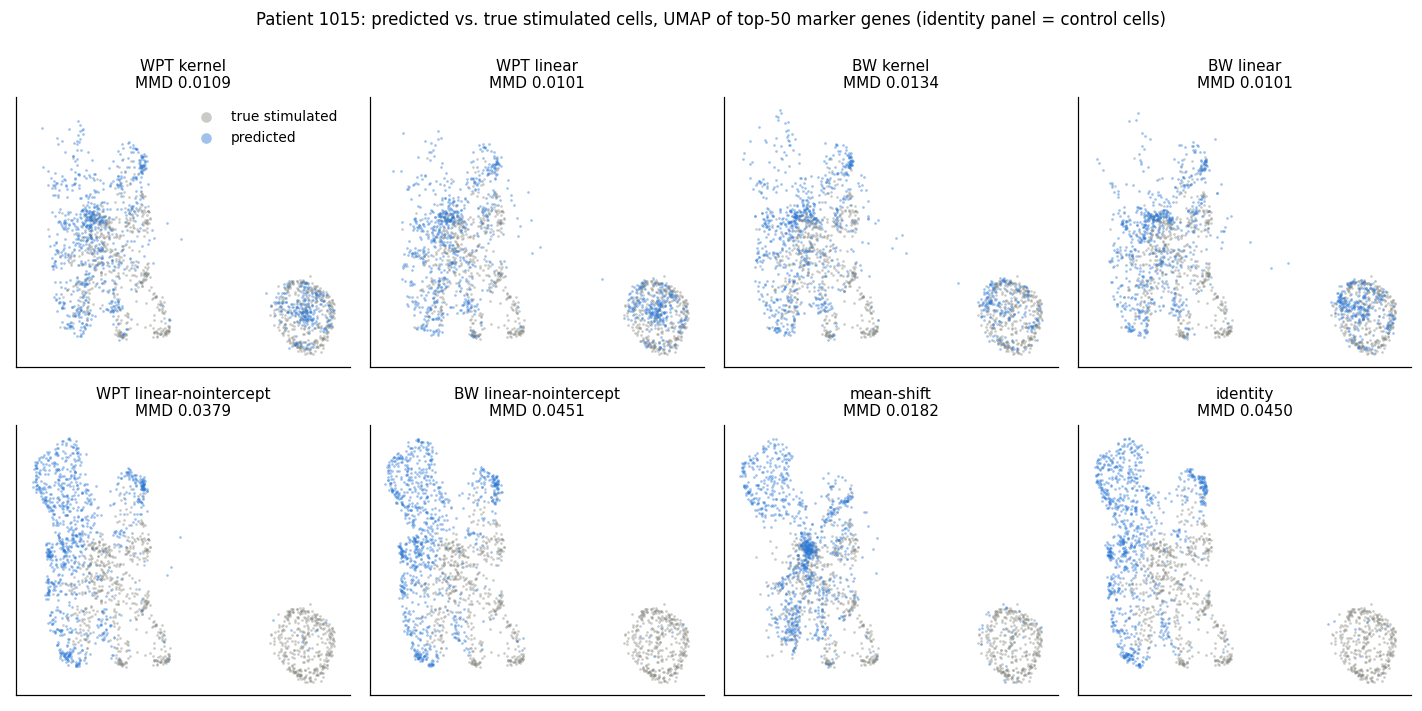

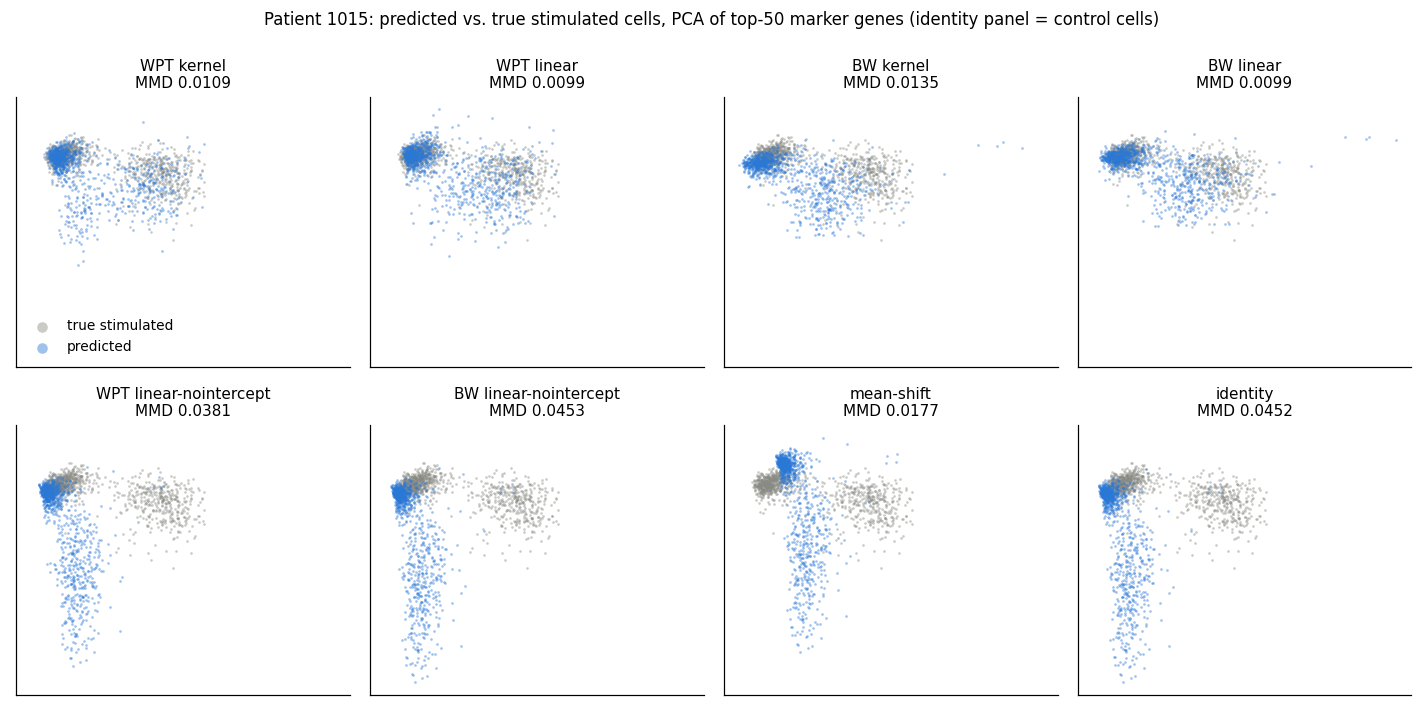

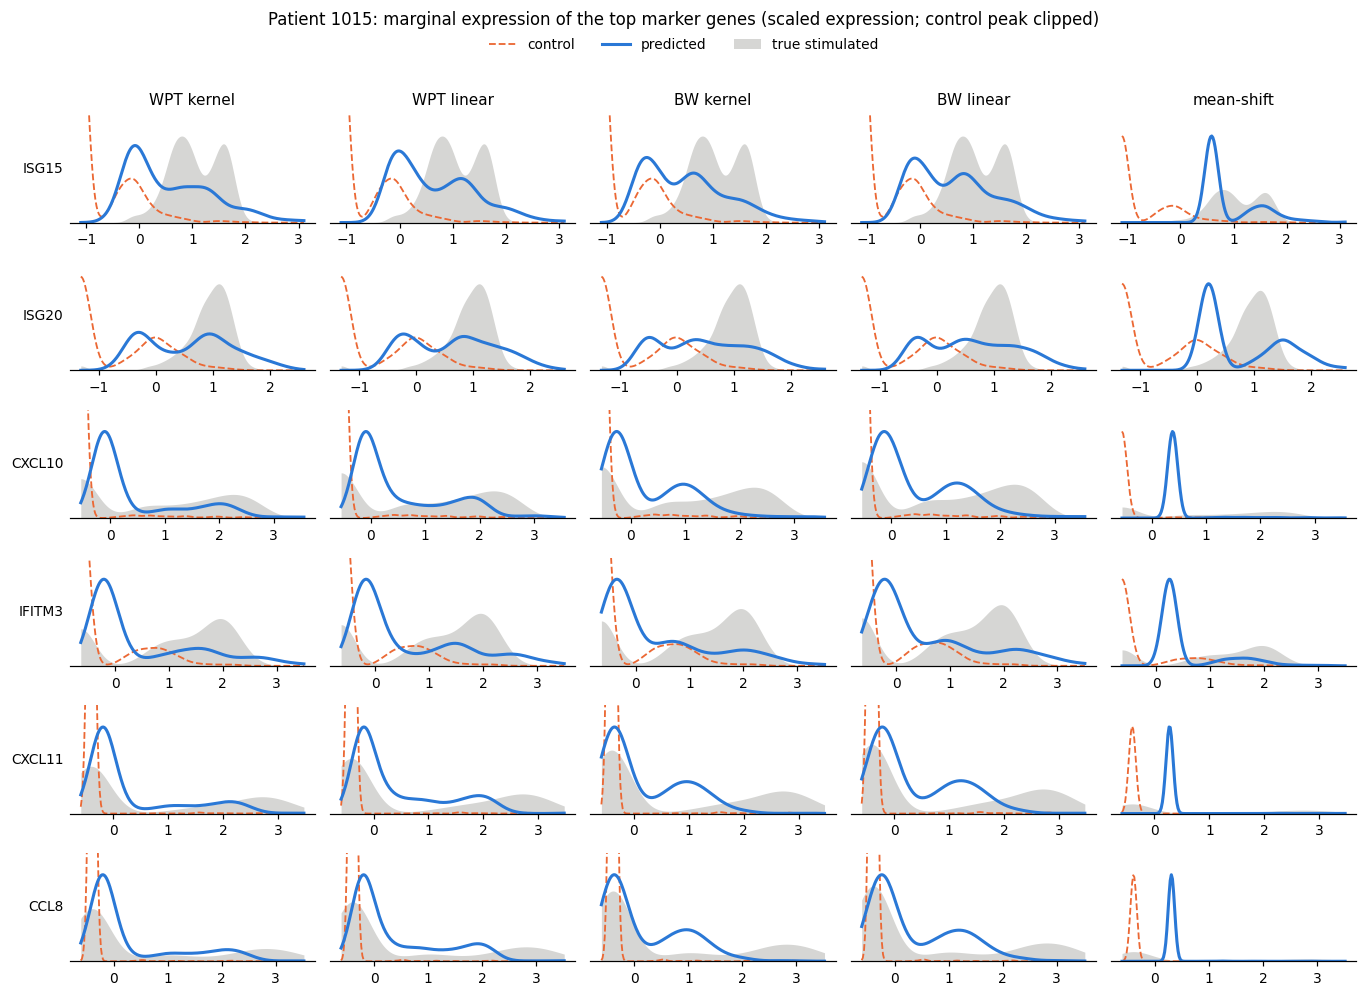

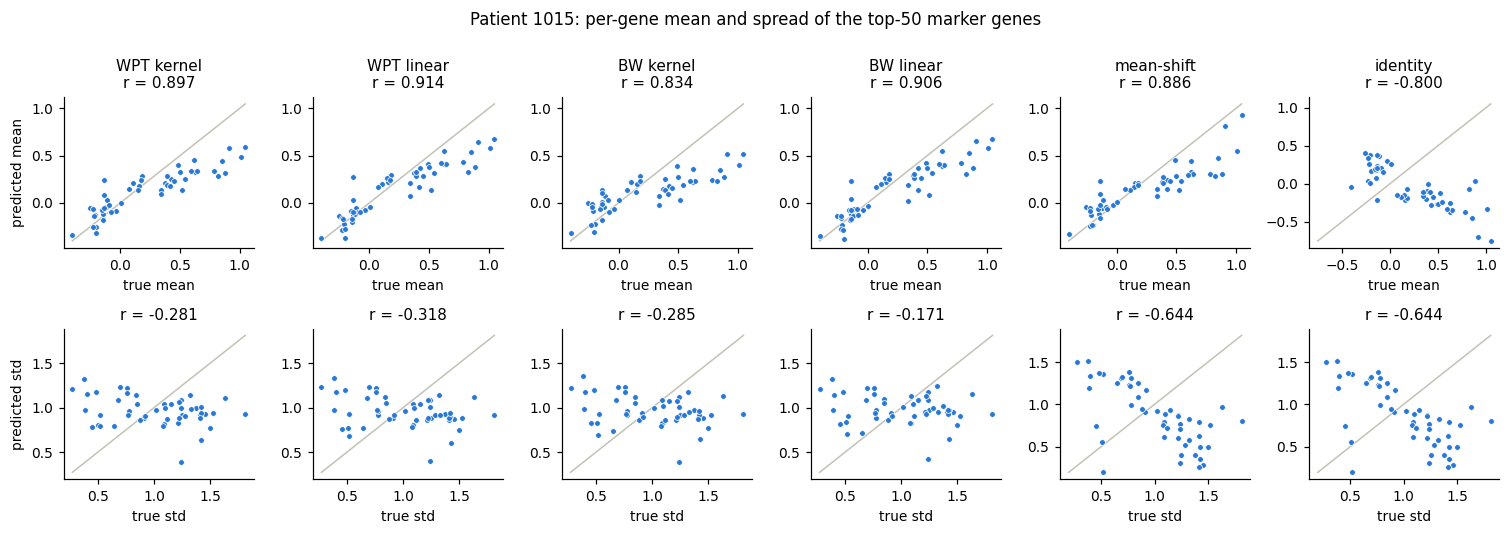

In [4]:
report(1015)

## Held-out patient 1256

patient 1256: 1265 control test cells, 1100 stimulated test cells


PCA dim  bandwidth / ridge  inner-CV MMD
geom method                                                      
bw   kernel                   50              0.250        0.0110
     linear                   50              0.001        0.0107
     linear-nointercept       10              0.001        0.0409
wpt  kernel                   50              0.100        0.0100
     linear                   30              0.001        0.0111
     linear-nointercept       30              0.001        0.0339

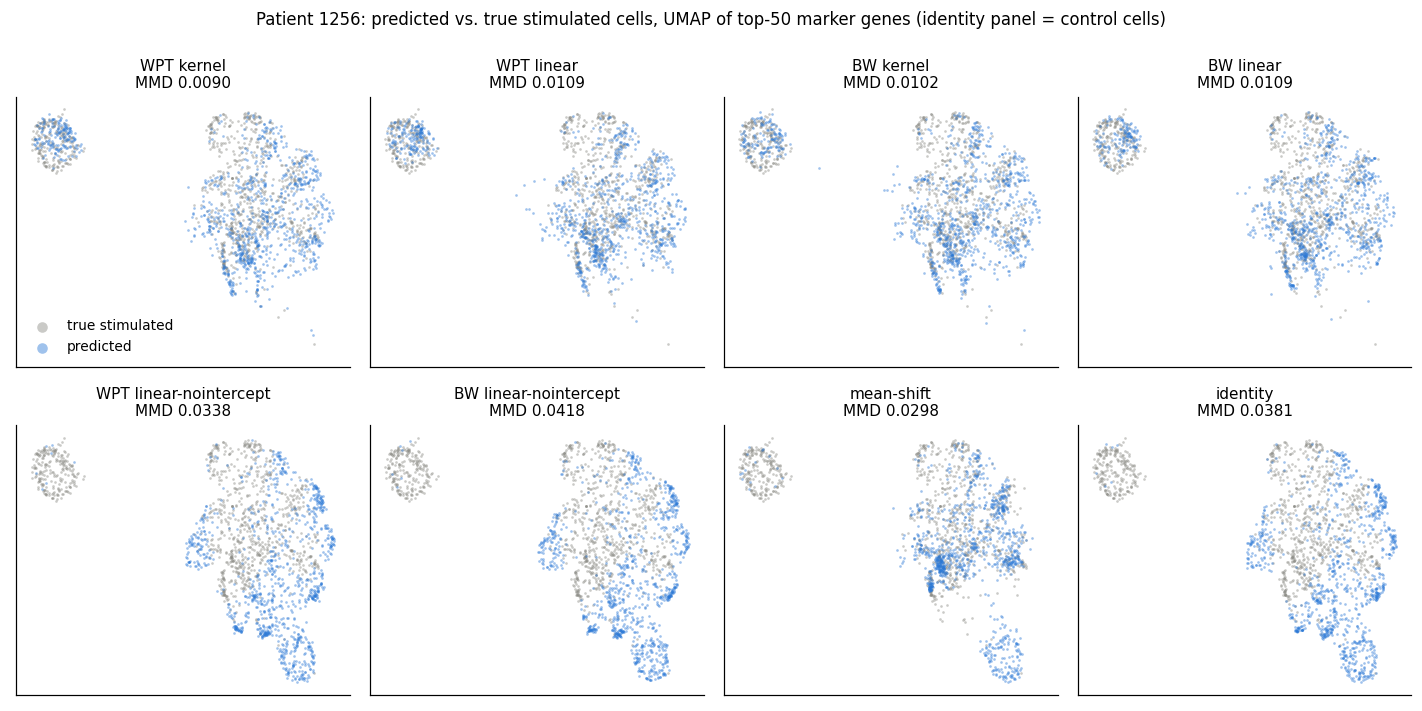

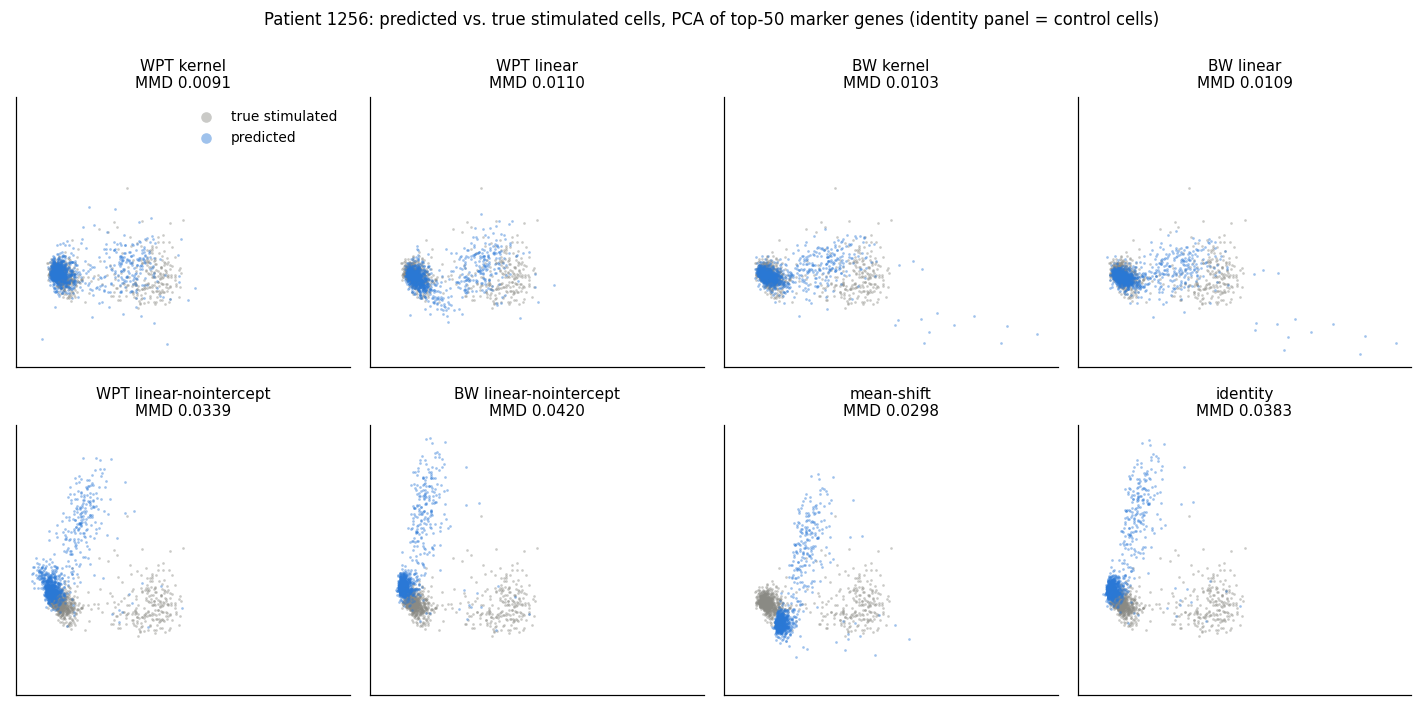

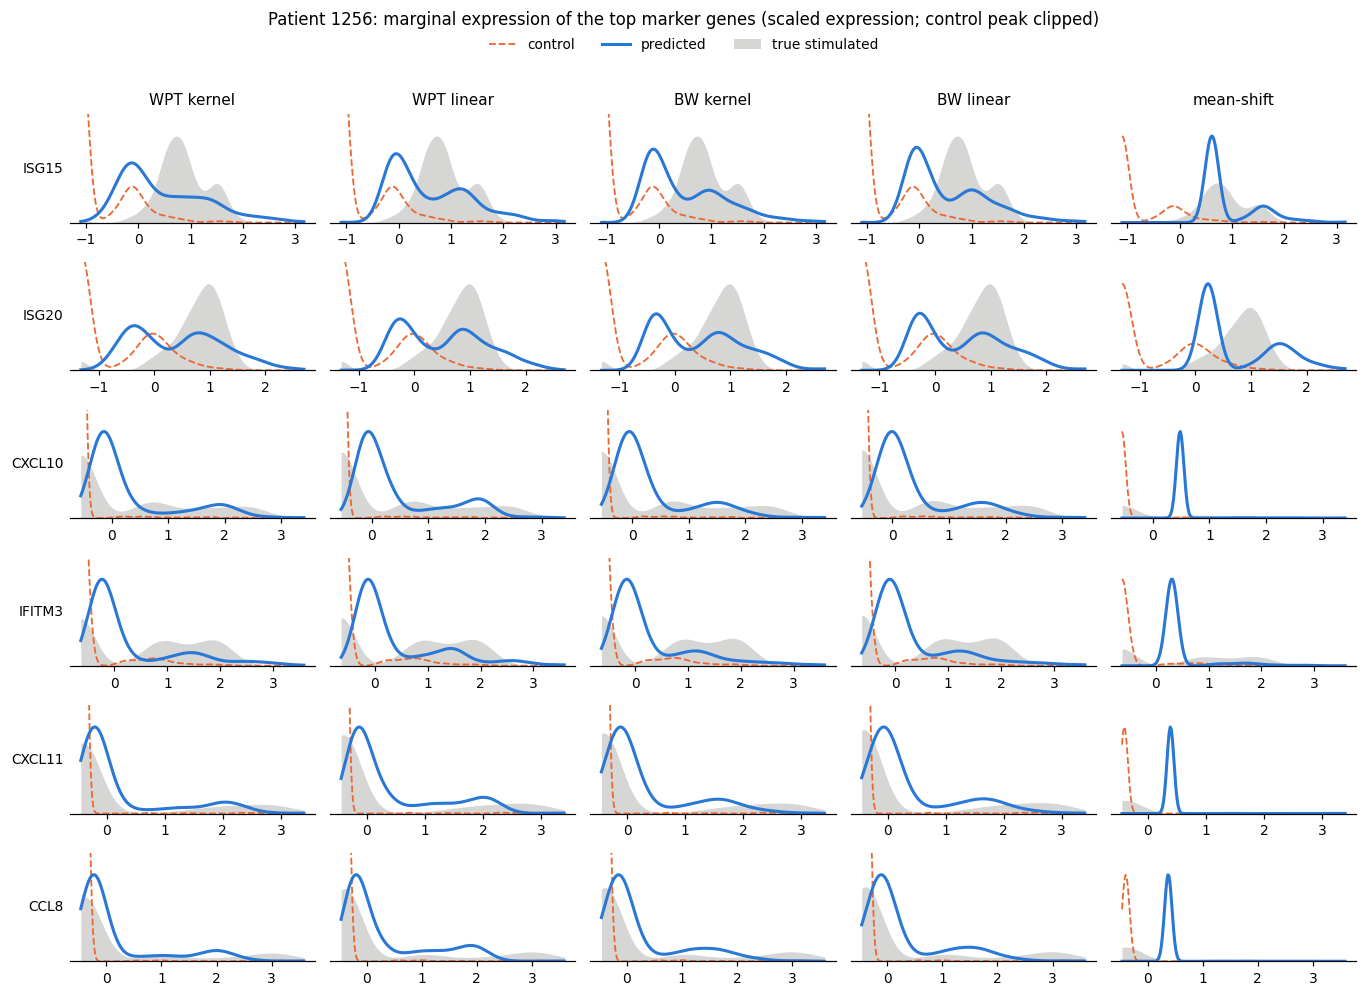

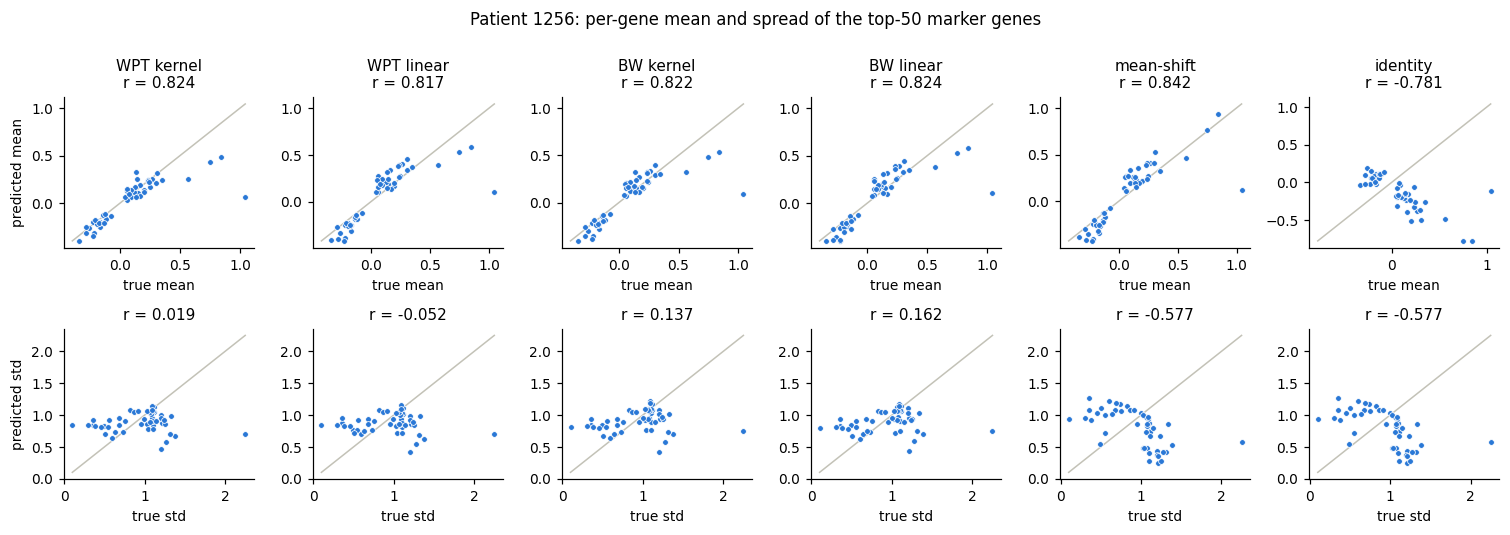

In [5]:
report(1256)

## MMD summary against the numbers reported by Bunne et al.

MMD on the top-50 marker genes, 1,000 cells, 10 bootstraps of the test set (bars = mean, whiskers = ± 1 sd).
The CellOT / scGen / cAE values are those published as Source Data for Extended Data Fig. 3; everything else is computed here.

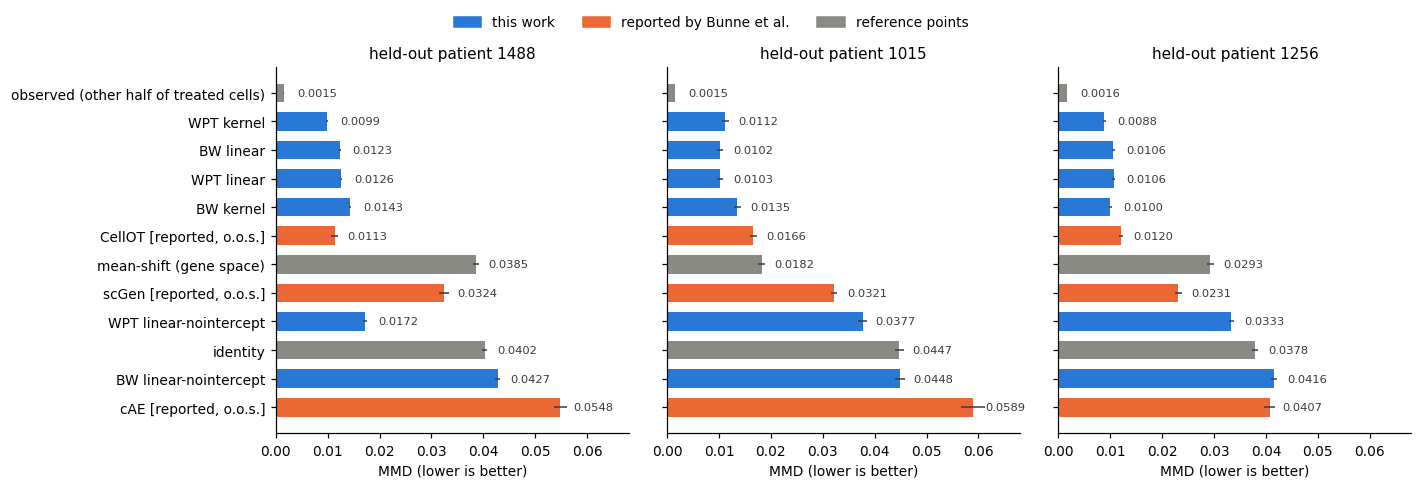

In [6]:
res = pd.read_csv(f"{ROOT}/results/all_results.csv")
res = res[(res.metric == "mmd") & (res.ncells == 1000) & res.holdout.isin([1488, 1015, 1256])]
res = res[~res.model.str.contains("i.i.d.")]
agg = res.groupby(["model", "holdout"]).value.agg(["mean", "std"]).reset_index()
order = agg.groupby("model")["mean"].mean().sort_values().index
kind = lambda m: "reported" if "reported" in m else ("ours" if m.split()[0] in ("WPT", "BW") else "reference")
COL = {"ours": "#2a78d6", "reported": "#eb6834", "reference": "#8a8a84"}
fig, axes = plt.subplots(1, 3, figsize=(13, 4.2), sharey=True, sharex=True)
for ax, K in zip(axes, (1488, 1015, 1256)):
    a = agg[agg.holdout == K].set_index("model").loc[order[::-1]]
    ax.barh(a.index, a["mean"], xerr=a["std"], color=[COL[kind(m)] for m in a.index], height=0.65,
            error_kw=dict(ecolor="#3b3b38", lw=1))
    for y, v in enumerate(a["mean"]): ax.text(v + 0.0025, y, f"{v:.4f}", va="center", fontsize=7.5, color="#3b3b38")
    ax.set_title(f"held-out patient {K}"); ax.set_xlabel("MMD (lower is better)"); ax.set_xlim(0, 0.068)
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in COL.values()]
fig.legend(handles, ["this work", "reported by Bunne et al.", "reference points"], loc="upper center", ncol=3, bbox_to_anchor=(0.5, 1.06))
fig.tight_layout(); plt.show()